# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 **without ImageNet pretraining and without tuning** (`NO_TUNING_ARCH_HYPERPARAMS["resnet18"]`), then saves its results and weights to disk for the results notebook. This is the baseline role AlexNet used to play — see `wwtw_utils.py`'s `ARCH_HYPERPARAMS` comment for why the baseline is now the *same* architecture as the tuned, pretrained `resnet18` run rather than a different one.


In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): Waterval
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 709 | Val: 170 | Test: 864


## Build dataloaders + class weights for this architecture

In [2]:
cfg = NO_TUNING_ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (ResNet-18, trained from scratch)

In [3]:
# ---------------------------------------------------------
# Define the CNN (ResNet-18, trained from scratch — no ImageNet weights)
# ---------------------------------------------------------
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18 (scratch)] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.0976 acc 0.498 | val loss 1.0571 acc 0.576 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 1.0504 acc 0.630 | val loss 0.9318 acc 0.624 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 1.0469 acc 0.580 | val loss 0.9815 acc 0.671


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 1.0253 acc 0.652 | val loss 0.7254 acc 0.712 *


...

[ResNet-18 (scratch)] Epoch  47/100 | LR: 1.00e-07 | train loss 0.6040 acc 0.752 | val loss 0.6029 acc 0.706


[ResNet-18 (scratch)] Epoch  48/100 | LR: 1.00e-07 | train loss 0.6229 acc 0.748 | val loss 0.6239 acc 0.712


[ResNet-18 (scratch)] Epoch  49/100 | LR: 1.00e-07 | train loss 0.6429 acc 0.756 | val loss 0.6331 acc 0.706


[ResNet-18 (scratch)] Epoch  50/100 | LR: 1.00e-07 | train loss 0.5965 acc 0.759 | val loss 0.7217 acc 0.676


[ResNet-18 (scratch)] Epoch  51/100 | LR: 1.00e-07 | train loss 0.6051 acc 0.762 | val loss 0.6074 acc 0.700

[ResNet-18 (scratch)] No val loss improvement for 10 epochs — stopping early at epoch 51.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.5839)


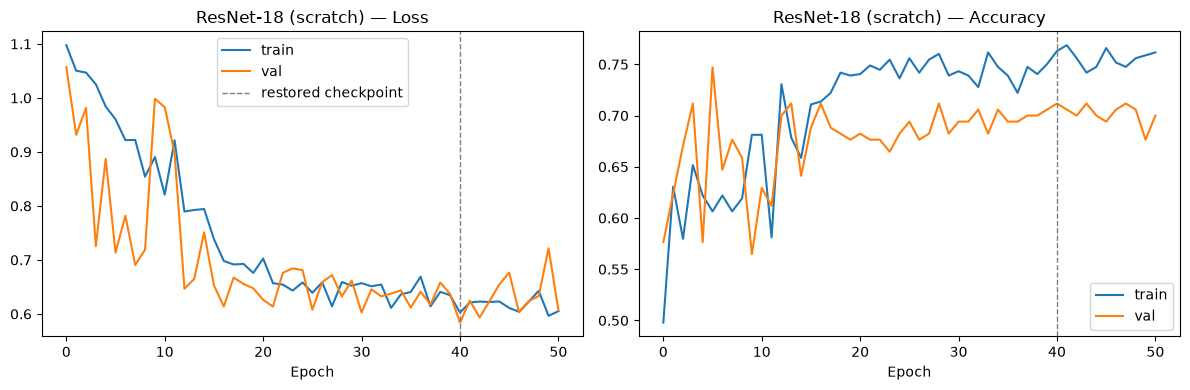

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.487


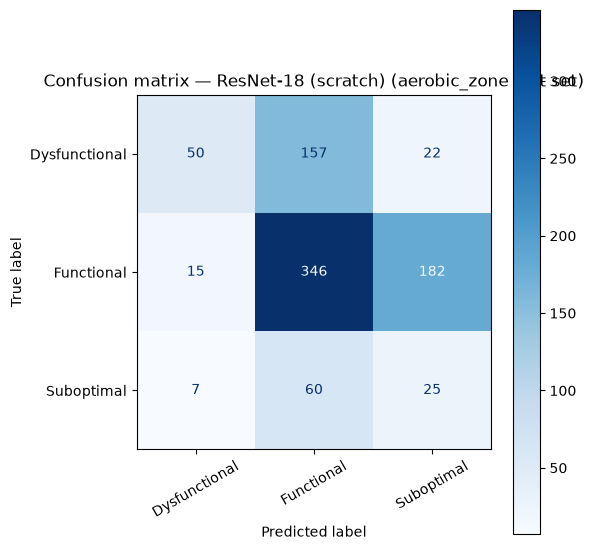

               precision    recall  f1-score   support

Dysfunctional      0.694     0.218     0.332       229
   Functional      0.615     0.637     0.626       543
   Suboptimal      0.109     0.272     0.156        92

     accuracy                          0.487       864
    macro avg      0.473     0.376     0.371       864
 weighted avg      0.582     0.487     0.498       864



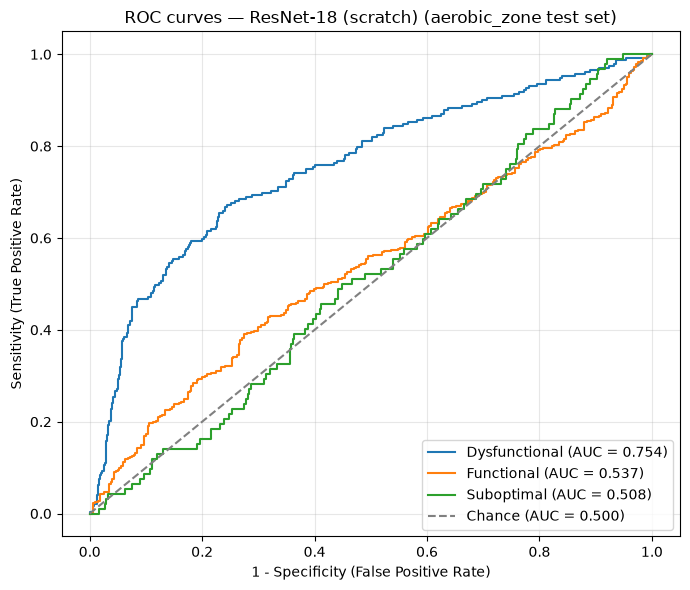

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.754
  Functional     : 0.537
  Suboptimal     : 0.508

Mean AUC (over 3/3 classes with test examples): 0.600


(np.float64(0.48726851851851855),
 {'Dysfunctional': 0.7543513392703641,
  'Functional': 0.5371909835172085,
  'Suboptimal': 0.5080254561838251})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_Waterval.pkl
Saved model weights to ../models/pad/aerobic_zone_resnet18_scratch_cnn.pt
